
# Vector KRR for Dipole Moments
In the previous example we had the case where the differentiation of a scalar
value resulted in a vector value of interest. More often, one wishes to directly train on a
vector valued property to predict the vector valued property.

This example demonstrates vector-valued KRR for predicting electronic dipole
moments directly as 3D vectors. We compare the use of an isotropic coupling kernel,
which essentially boils down to using individual KRR for each component of the dipole moment
and the use a output covariance matrix that is learned during training. Readers will note
that this latter approach resembles the multi-task GPR.

With the isotropic kernel K(x,x') = k(x,x') I_d, the model is equivalent to
three independent scalar KRRs. The coupled formulation K(x,x') = k(x,x') T
learns a 3×3 positive semi definite output covariance matrix that captures cross-component
correlations, adding 6 free parameters that are learned during training.


## Imports



In [1]:
import numpy as np
import matplotlib.pyplot as plt

from mfml_qc.datasets import load_nitrophenol_data
from mfml_qc.vector_krr import VectorKRR, CoupledVectorKRR

## Load and Split Data
We load the QeMFi nitrophenol dataset and extract the highest-fidelity
electronic dipole moments. A random 512/3000 train/test split is used.



In [2]:
dataset = load_nitrophenol_data()
X_CM = dataset["X_CM"]
DPe_hf = dataset["DPe"][:, -1, :]

N_TRAIN = 512  # at the highest fidelity
N_TEST = 3000

rng = np.random.RandomState(42)
perm = rng.permutation(len(DPe_hf))
train_idx, test_idx = perm[:N_TRAIN], perm[N_TRAIN : N_TRAIN + N_TEST]

X_train = X_CM[train_idx]
X_test = X_CM[test_idx]
Y_train = DPe_hf[train_idx]
Y_test = DPe_hf[test_idx]

Y_mean = np.mean(Y_train, axis=0)
Y_train_c = Y_train - Y_mean

## Train Both Models
The isotropic model uses the identity as output covariance (T = I),
while the coupled model learns a full 3×3 PSD matrix T = L L^T via
Nelder-Mead optimisation on a held-out validation set. This validation
set is taken from the training data itself, here, we will use
a 15% validation size. In practice, therefore, the coupled
approach 'sees' the same amount of data as the isotropic case.



In [3]:
model_iso = VectorKRR(kernel_type="gaussian", sigma=250.0, reg=1e-10)
model_iso.train(X_train, Y_train_c)
pred_iso = model_iso.predict(X_test) + Y_mean

model_coupled = CoupledVectorKRR(
    kernel_type="gaussian", sigma=250.0, reg=1e-10, val_fraction=0.15, max_opt_iter=500
)
model_coupled.train(X_train, Y_train_c)
pred_coupled = model_coupled.predict(X_test) + Y_mean

## Evaluate
We compute the component-wise MAE, overall MAE, mean cosine similarity,
and mean angular error for both models.



In [4]:
def eval_model(pred, true):
    comp_mae = np.mean(np.abs(pred - true), axis=0)
    overall = np.mean(np.abs(pred - true))
    mag_p = np.linalg.norm(pred, axis=-1)
    mag_t = np.linalg.norm(true, axis=-1)
    dot = np.sum(pred * true, axis=-1)
    denom = np.maximum(mag_p * mag_t, 1e-12)
    cos_sim = np.clip(dot / denom, -1.0, 1.0)
    return comp_mae, overall, cos_sim


comp_iso, mae_iso, cos_iso = eval_model(pred_iso, Y_test)
comp_cpl, mae_cpl, cos_cpl = eval_model(pred_coupled, Y_test)

## Comparison Figure
A 2×3 parity plot grid shows predicted vs true values for each dipole
component. The top row is the isotropic model, the bottom row the
coupled model. Points are coloured by dipole magnitude.



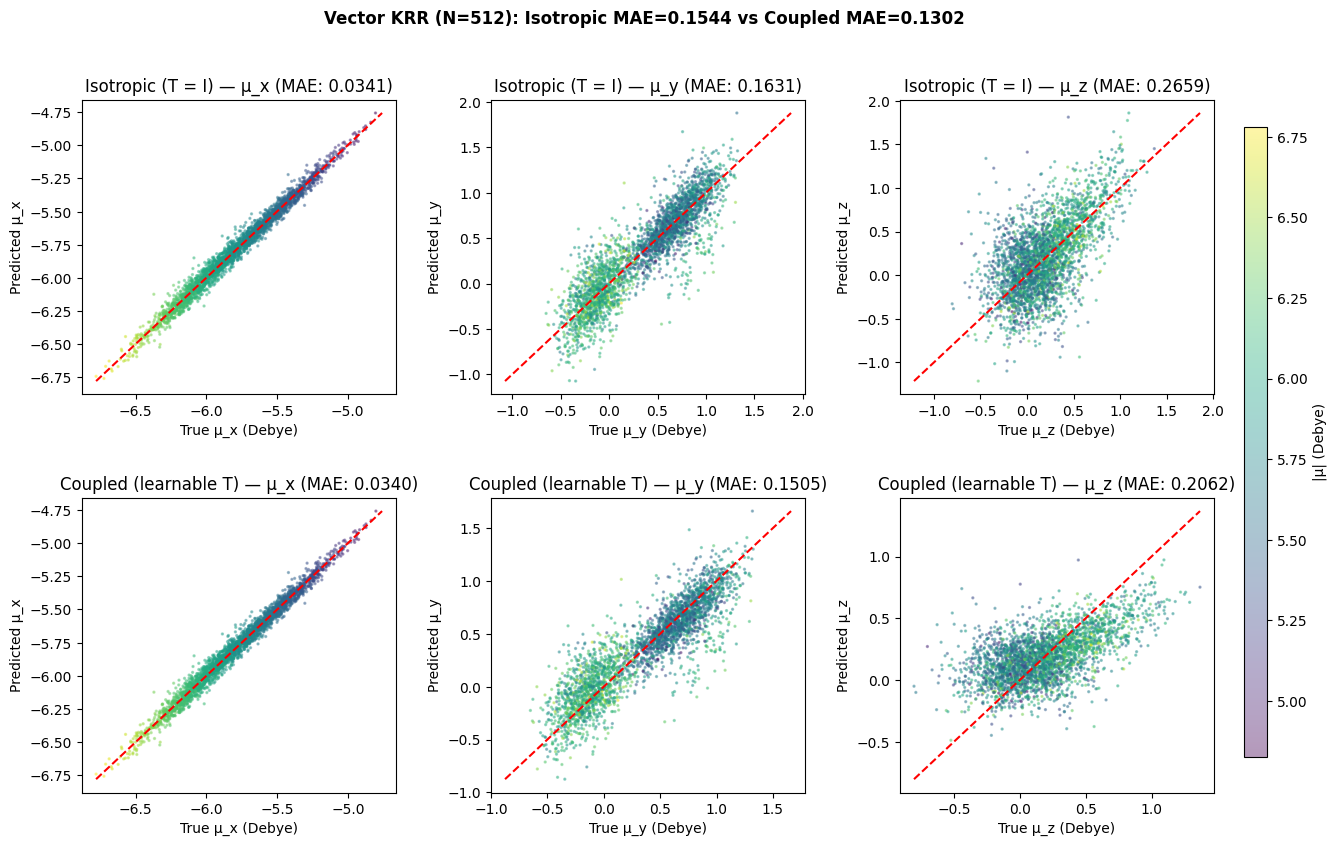

In [5]:
fig, axes = plt.subplots(
    2, 3, figsize=(15, 9), gridspec_kw={"hspace": 0.35, "wspace": 0.3}
)

mag_true = np.linalg.norm(Y_test, axis=-1)
cmap = plt.cm.viridis
vmin, vmax = mag_true.min(), mag_true.max()
comp_labels = ["μ_x", "μ_y", "μ_z"]
rows = [
    ("Isotropic (T = I)", pred_iso, comp_iso),
    ("Coupled (learnable T)", pred_coupled, comp_cpl),
]

for row, (label, pred, comp_mae) in enumerate(rows):
    for c in range(3):
        sc = axes[row, c].scatter(
            Y_test[:, c],
            pred[:, c],
            s=2,
            alpha=0.4,
            c=mag_true,
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
        )
        lo = min(Y_test[:, c].min(), pred[:, c].min())
        hi = max(Y_test[:, c].max(), pred[:, c].max())
        axes[row, c].plot([lo, hi], [lo, hi], "r--", lw=1.5)
        axes[row, c].set_xlabel(f"True {comp_labels[c]} (Debye)")
        axes[row, c].set_ylabel(f"Predicted {comp_labels[c]}")
        axes[row, c].set_title(f"{label} — {comp_labels[c]} (MAE: {comp_mae[c]:.4f})")

fig.subplots_adjust(right=0.88)
cbar_ax = fig.add_axes([0.90, 0.15, 0.015, 0.7])
fig.colorbar(sc, cax=cbar_ax).set_label("|μ| (Debye)")

fig.suptitle(
    f"Vector KRR (N={N_TRAIN}): "
    f"Isotropic MAE={mae_iso:.4f} vs Coupled MAE={mae_cpl:.4f}",
    fontsize=12,
    fontweight="bold",
)
plt.show()